# 02b · Training the Fourier Neural Operator (model under test)

This notebook trains the **FNO** used in the report: 3 training grids (128, 64, 32 points) × 3 seeds = **9 runs**.
Approximate time on a laptop CPU: ≈6 min per run at 128 points, 3 min at 64, 2 min at 32, so **about 35 minutes**.
The CNN has its own notebook (`02a_train_cnn`).

Every run shows a **live convergence plot** while it trains, so you can watch it and tune hyperparameters.
Trained models go to `checkpoints/` and are used by notebooks 03 and 04.

**Sections:** 1 data and split · 2 the model · 3 loss and live monitor · 4 hyperparameters (and why there is no early
stopping) · 5 training loop · 6 train every run · 7 overview of all curves · 8 sandbox for trying other hyperparameters.

**Requirements:** `pip install numpy pandas matplotlib torch jupyter`

In [1]:
# Which runs to train. For a 7-minute check use TRAIN_GRIDS = [128] and SEEDS = [0]  (or [32] for ~2 minutes).
TRAIN_GRIDS = [128, 64, 32]
SEEDS = [0, 1, 2]
SKIP_EXISTING = True           # skip runs whose checkpoint is already saved (their saved curve is shown instead)
MODEL = "fno"

In [2]:
import os, json, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display

DATA = os.path.join("..", "data")
CKPT = "checkpoints"
os.makedirs(CKPT, exist_ok=True)

# Train on the CPU so that runs are reproducible (bit-for-bit on the same machine).
DEVICE = "cpu"
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.14.1+cu130 | threads: 2


## 1. Training data and the train / validation split

**Coarser training grids.** The kit's training data is on 128 points. Because the kit built it by taking every
8th point of a 1024-point simulation, we can make 64- and 32-point training data the same way: every 2nd or
every 4th point. No new data is needed and the physics is unchanged.

**Split by trajectory.** The 240 training rows are 48 trajectories × 5 start times, stored trajectory by trajectory.
If we split *rows* at random, the same trajectory would appear in both training and validation. Its five snapshots
are strongly related, so validation would look better than it really is (leakage). Instead we hold out **10 whole
trajectories** (50 rows) for validation and train on the other **38** (190 rows). The split is fixed
(`RandomState(0)`) and is the **same for every model and every seed**, in both training notebooks. That is what
makes the CNN–FNO comparison "matched".

In [3]:
N_TRAJ, PER_TRAJ = 48, 5

def load_train(n_grid):
    d = np.load(os.path.join(DATA, "train.npz"))
    step = 128 // n_grid                              # 1 for 128 points, 2 for 64, 4 for 32
    X = d["field"][:, ::step].astype(np.float32)      # input:  u(x, t)
    Y = d["target"][:, ::step].astype(np.float32)     # target: u(x, t + dt)
    return X, Y

def fixed_split():
    perm = np.random.RandomState(0).permutation(N_TRAJ)   # shuffle trajectory ids 0..47
    val_traj, train_traj = perm[:10], perm[10:]
    rows = lambda ts: np.concatenate([np.arange(t * PER_TRAJ, (t + 1) * PER_TRAJ) for t in ts])
    return rows(train_traj), rows(val_traj)

tr, va = fixed_split()
print("training rows:", len(tr), "| validation rows:", len(va),
      "| validation trajectories:", sorted(set(va // PER_TRAJ)))
for n in (128, 64, 32):
    print(f"{n:>3}-point training data:", load_train(n)[0].shape)

training rows: 190 | validation rows: 50 | validation trajectories: [np.int64(4), np.int64(7), np.int64(10), np.int64(26), np.int64(29), np.int64(30), np.int64(32), np.int64(34), np.int64(37), np.int64(40)]
128-point training data: (240, 128)
 64-point training data: (240, 64)
 32-point training data: (240, 32)


## 2. The model: a Fourier Neural Operator

The FNO (Li et al., 2021) has three parts:

1. **Lift:** at every grid point, map the 2 input numbers (the value $u(x)$ and the position $x$) to 64 channels.
2. **Four Fourier layers.** Each computes
   $$v \;\mapsto\; \mathrm{GELU}\big(\,W v \;+\; \mathcal{F}^{-1}\big(R \cdot \mathcal{F} v\big)\big)$$
   - $\mathcal{F}v$: Fourier transform of each channel (field → waves).
   - $R\cdot$: multiply the **lowest `modes` wavenumbers** by learned complex weights (a 64×64 matrix per wavenumber),
     and set all higher wavenumbers to zero.
   - $\mathcal{F}^{-1}$: back to the grid (waves → field).
   - $W v$: a plain linear map applied at each point separately (a 1×1 convolution). It works on all scales.
   - GELU: the non-linearity, applied point by point.
3. **Projection:** at every point, map 64 channels back to one output value.

**Why it should be resolution-independent.** The learned weights $R$ belong to *wavenumbers*, not to grid points.
Wavenumber 5 means "5 cycles across the domain" on any grid, so the same weights can be used on 128, 256 or 512
points without retraining. The point-wise parts (lift, $W$, GELU, projection) do not depend on the grid either.

**How many modes.** We keep `modes = N_train / 2`: every wavenumber the training grid can represent except the
Nyquist one (64 at 128 points, 32 at 64, 16 at 32). Then nothing is thrown away *inside* the training grid, so any
growth on finer grids comes from the change of grid.

**One thing to remember for the analysis.** The position input $x \in [0, 1)$ is **not periodic**: it jumps from
almost 1 back to 0 at the edge of the domain, while the field itself wraps around smoothly. Notebook 04 shows that a
large share of the FNO's error sits right at the domain edges, which is probably caused by this jump.

In [4]:
def make_input(u):
    # (batch, N) -> (batch, N, 2): channel 0 = u(x), channel 1 = the position x in [0, 1)
    batch, n_points = u.shape
    x = torch.linspace(0, 1, n_points + 1, device=u.device)[:-1]   # N evenly spaced points, endpoint excluded
    return torch.stack([u, x.expand(batch, n_points)], dim=-1)


class SpectralConv1d(nn.Module):
    # the Fourier part of one FNO layer: F^-1( R * F v ), keeping only the lowest `modes` wavenumbers
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        # one complex (in x out) weight matrix per kept wavenumber
        self.weights = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):                                   # x: (batch, channels, N)
        batch, _, n_points = x.shape
        x_freq = torch.fft.rfft(x)                          # field -> wavenumbers 0 .. N/2
        out_freq = torch.zeros(batch, self.weights.shape[1], n_points // 2 + 1,
                               dtype=torch.cfloat, device=x.device)   # higher wavenumbers stay 0
        k = min(self.modes, n_points // 2 + 1)
        # for each kept wavenumber: mix the channels with that wavenumber's weight matrix
        out_freq[:, :, :k] = torch.einsum("bix,iox->box", x_freq[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out_freq, n=n_points)        # wavenumbers -> field on the SAME grid


class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)                                          # (u, x) -> width channels
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])   # point-wise W
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))  # width -> 1

    def forward(self, u):                                   # u: (batch, N)
        x = self.lift(make_input(u)).permute(0, 2, 1)       # (batch, width, N)
        for fourier, local in zip(self.spec, self.w):
            x = nn.functional.gelu(fourier(x) + local(x))   # one Fourier layer
        return self.proj(x.permute(0, 2, 1)).squeeze(-1)   # (batch, N)

for m in (64, 32, 16):
    print(f"FNO with {m} modes: {sum(p.numel() for p in FNO1d(modes=m).parameters()):,} parameters")

FNO with 64 modes: 1,073,857 parameters
FNO with 32 modes: 549,569 parameters
FNO with 16 modes: 287,425 parameters


## 3. Loss and the live training monitor

**Loss.** The model minimises the **relative $L^2$ error** averaged over the batch,
$\lVert \hat u - u \rVert_2 / \lVert u \rVert_2$. Dividing by the size of the true field puts every example on the
same scale. It is the same quantity we report in the evaluation.

**Monitor.** Every run draws a convergence plot that **updates live while it trains** (every `PLOT_EVERY` epochs):
- **left:** training error and validation error per epoch (log scale). The dot marks the best validation epoch,
  the weights we keep;
- **right:** the learning rate per epoch.

How to read it when tuning:
- **Both curves still falling at the end:** training is too short or the learning rate too low.
- **Validation rising while training keeps falling:** overfitting. The best-validation checkpoint protects you, but a
  smaller model or more regularisation may help.
- **Very jumpy curves:** the learning rate is too high or the batch is too small.
- **A big gap between the curves from the start:** the validation trajectories are harder than the training ones.
  Compare across seeds before concluding anything.

In [5]:
PLOT_EVERY = 10          # redraw the live plot every this many epochs (bigger = faster notebook)

def rel_l2_torch(pred, target):
    return (torch.linalg.vector_norm(pred - target, dim=-1)
            / torch.linalg.vector_norm(target, dim=-1)).mean()

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)            # fixes the weight initialisation


def draw_curves(axes, hist, title, baseline=None):
    # hist: dict with lists 'train', 'val', 'lr' (one value per epoch)
    ax, ax_lr = axes
    ax.clear(); ax_lr.clear()
    ep = np.arange(1, len(hist["val"]) + 1)
    if baseline is not None:           # optional reference run (used by the sandbox)
        bep = np.arange(1, len(baseline["val"]) + 1)
        ax.plot(bep, baseline["val"], color="#9a9a9a", lw=1, label="validation (saved model)")
    ax.plot(ep, hist["train"], color="#86b6ef", lw=1.2, label="training")
    ax.plot(ep, hist["val"], color="#104281", lw=1.5, label="validation")
    best = int(np.argmin(hist["val"]))
    ax.scatter([best + 1], [hist["val"][best]], color="#eb6834", zorder=3, s=25,
               label=f"best val {hist['val'][best]:.5f} (epoch {best + 1})")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("relative L2 error")
    ax.set_title(title, fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False)
    ax_lr.plot(ep, hist["lr"], color="#6b6b6b")
    ax_lr.set_xlabel("epoch"); ax_lr.set_ylabel("learning rate"); ax_lr.set_title("learning rate", fontsize=10)
    ax_lr.grid(alpha=0.3)


class LiveMonitor:
    # draws one convergence plot per run and redraws it in place while the run trains
    def __init__(self, title, baseline=None):
        self.title, self.baseline = title, baseline
        self.fig, self.axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)            # stop Jupyter from drawing a second copy at the end of the cell

    def update(self, hist, epoch, final=False):
        if final or epoch % PLOT_EVERY == 0:
            draw_curves(self.axes, hist, f"{self.title} (epoch {epoch + 1})", self.baseline)
            self.fig.tight_layout()
            self.handle.update(self.fig)

## 4. Hyperparameters

These are the settings from `models/FNO_submission/FNO_final_model.ipynb`. Change them here to tune. Everything below
reads from this dictionary.

| Setting | Meaning |
|---|---|
| `width`, `n_layers` | channels inside the network and number of Fourier layers |
| `modes_rule` | how many Fourier modes to keep for a given training grid (default: half the grid size) |
| `lr`, `weight_decay` | starting learning rate and L2 weight penalty of Adam |
| `batch_size` | examples per gradient step |
| `epochs` | training length; the **cosine schedule** lowers the learning rate smoothly from `lr` to 0 over exactly this many epochs |
| `early_stopping_patience` | `None` = off (default). A number = stop after that many epochs without improvement |

**Why early stopping is off.** The weights we keep are always the **best-validation** ones, so the FNO is already
protected against overfitting. Stopping *early* would hurt it, because of the cosine schedule:
- early on the learning rate is high, so the validation error jumps around and can go 40+ epochs without a new best
  while the model is still improving;
- most of the real improvement comes **late**, when the learning rate gets small.

We checked this. In all 9 runs the best validation epoch is between **453 and 490 of 500** (table in section 7).
Early stopping with the CNN's patience of 40 would have stopped around epoch 60–75 and kept a model
**6× worse** (128-point grid) or **3× worse** (32-point grid).
You can see the same pattern in the convergence plots below: the validation curve keeps falling until the very end.
The CNN is different: its learning rate is constant until halved, so it stops improving for good, and early stopping fits.

In [6]:
HP = dict(
    width=64, n_layers=4,                       # architecture
    modes_rule=lambda n_train: n_train // 2,    # Fourier modes kept: 64 at 128 pts, 32 at 64, 16 at 32
    lr=1e-3, weight_decay=1e-4, batch_size=16,  # optimiser
    epochs=500,                                 # length of the cosine schedule
    early_stopping_patience=None,               # None = off (see the explanation above)
)

## 5. The training loop

One epoch = one pass over the 190 training examples in random mini-batches, then one evaluation on the 50
validation examples. Each epoch records the average training loss, the validation error and the learning rate.

- After every epoch the cosine scheduler lowers the learning rate a little.
- If validation improves, the weights are copied as the new best.
- The function returns the **best-validation weights** (the same selection rule as the CNN), not the last ones.

The batch order comes from a `torch.Generator` seeded with the run's seed, so each run is exactly reproducible.

In [7]:
def train_fno(X, Y, tr, va, seed, hp, modes, monitor=None):
    set_seed(seed)
    model = FNO1d(modes=modes, width=hp["width"], n_layers=hp["n_layers"])
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=hp["epochs"])   # lr: hp["lr"] -> 0
    Xt, Yt, Xv, Yv = map(torch.tensor, (X[tr], Y[tr], X[va], Y[va]))
    g = torch.Generator().manual_seed(seed)                # controls the batch order
    hist = dict(train=[], val=[], lr=[])

    best, best_state, wait = np.inf, None, 0
    for ep in range(hp["epochs"]):
        hist["lr"].append(opt.param_groups[0]["lr"])       # learning rate used in this epoch
        model.train()
        order = torch.randperm(len(Xt), generator=g)
        batch_losses = []
        for s in range(0, len(Xt), hp["batch_size"]):
            i = order[s:s + hp["batch_size"]]
            loss = rel_l2_torch(model(Xt[i]), Yt[i])
            opt.zero_grad(); loss.backward(); opt.step()
            batch_losses.append(loss.item() * len(i))
        sched.step()

        model.eval()
        with torch.no_grad():
            val = rel_l2_torch(model(Xv), Yv).item()
        hist["train"].append(sum(batch_losses) / len(Xt))
        hist["val"].append(val)
        if monitor:
            monitor.update(hist, ep)

        if val < best:                                     # keep the best-validation weights
            best, wait = val, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if hp["early_stopping_patience"] is not None and wait >= hp["early_stopping_patience"]:
            break                                          # optional early stopping (off by default)

    if monitor:
        monitor.update(hist, ep, final=True)
    model.load_state_dict(best_state)
    return model, dict(best_val=best, epochs=ep + 1), hist

## 6. Train every FNO run

For each training grid and seed: train with the hyperparameters above (live plot), then save the weights, the
settings, the best validation error **and the training history** (the convergence curves) to `checkpoints/`.

Runs whose checkpoint already exists are **skipped**, and their saved curve is shown instead. So you can stop and
restart the notebook safely. To retrain from scratch, delete the matching files in `checkpoints/`
(or set `SKIP_EXISTING = False`).

> **If you change a hyperparameter, delete the old checkpoints** (or use the sandbox in the last section).
> Otherwise the skipped runs keep the old settings, and notebook 03 would mix models trained in different ways.

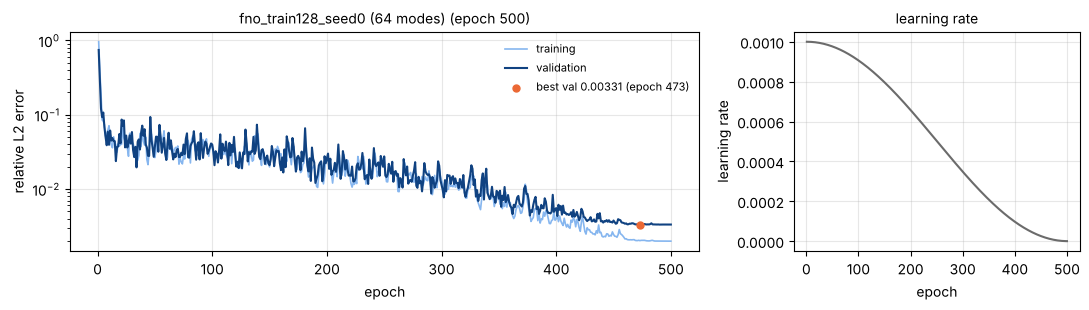

fno_train128_seed0: 500 epochs in 474.1 s, best validation error 0.00331


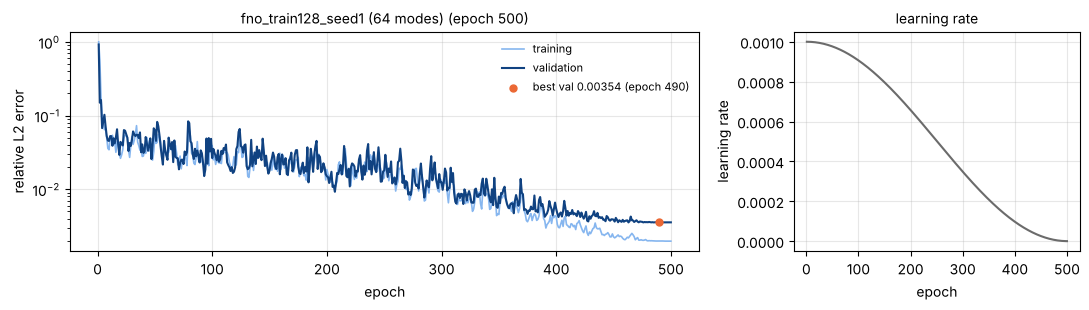

fno_train128_seed1: 500 epochs in 444.2 s, best validation error 0.00354


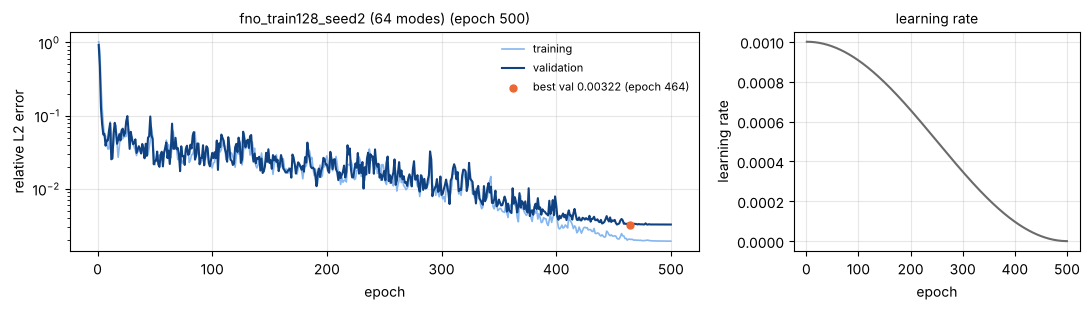

fno_train128_seed2: 500 epochs in 445.4 s, best validation error 0.00322


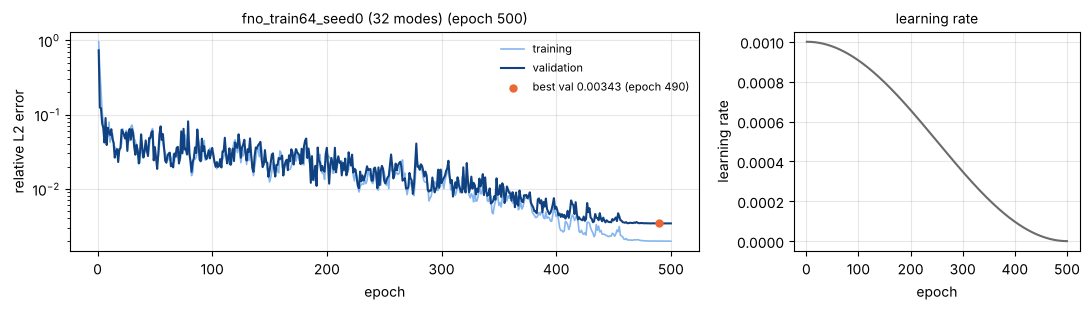

fno_train64_seed0: 500 epochs in 286.4 s, best validation error 0.00343


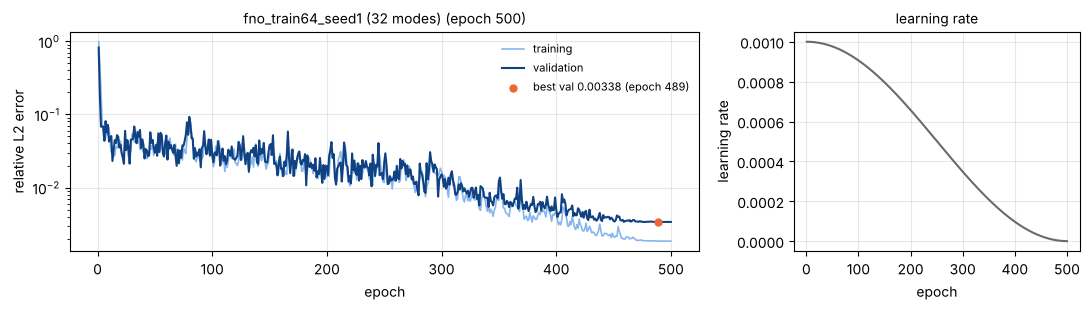

fno_train64_seed1: 500 epochs in 293.9 s, best validation error 0.00338


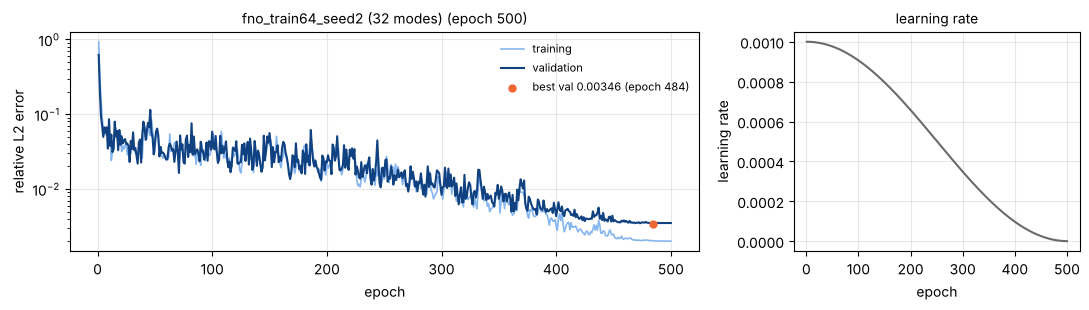

fno_train64_seed2: 500 epochs in 268.9 s, best validation error 0.00346


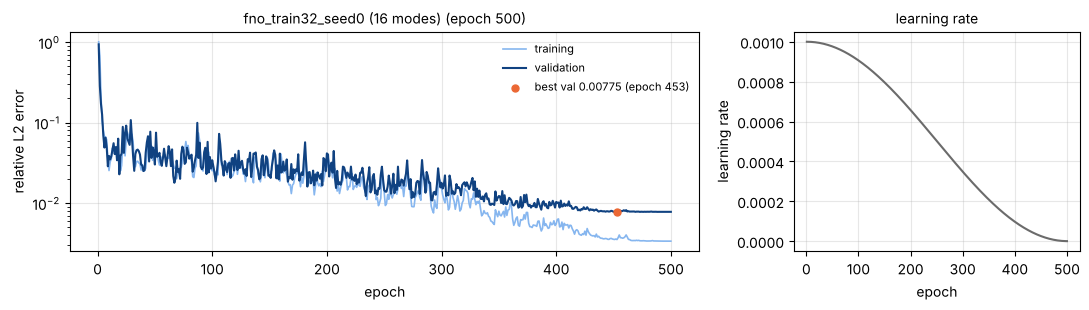

fno_train32_seed0: 500 epochs in 170.9 s, best validation error 0.00775


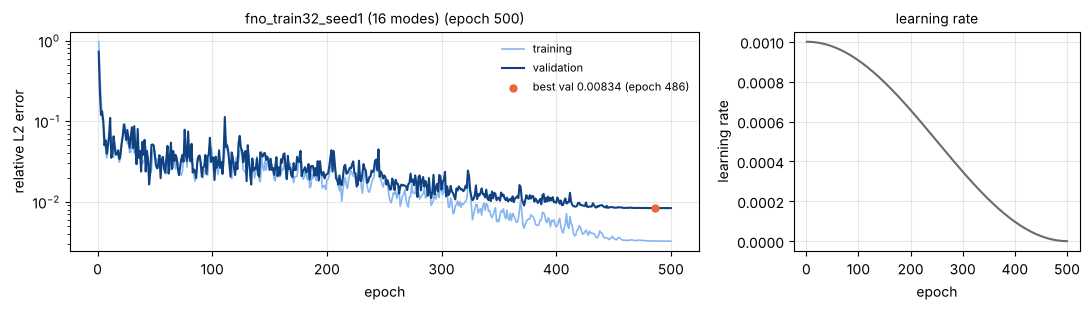

fno_train32_seed1: 500 epochs in 174.7 s, best validation error 0.00834


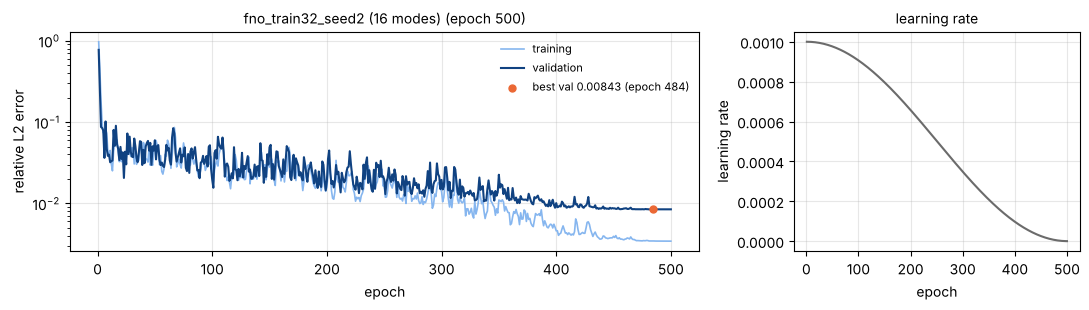

fno_train32_seed2: 500 epochs in 177.6 s, best validation error 0.00843


In [8]:
for n_train in TRAIN_GRIDS:
    X, Y = load_train(n_train)
    modes = HP["modes_rule"](n_train)
    for seed in SEEDS:
        tag = f"{MODEL}_train{n_train}_seed{seed}"
        path = os.path.join(CKPT, tag + ".pt")
        if SKIP_EXISTING and os.path.exists(path):
            ck = torch.load(path, map_location="cpu", weights_only=False)
            print(f"skip {tag}: checkpoint exists (best val {ck['info']['best_val']:.5f})")
            if ck.get("history"):                          # show its saved curve
                fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
                draw_curves(axes, ck["history"], f"{tag} (saved)"); plt.tight_layout(); plt.show()
            continue

        t0 = time.time()
        model, info, hist = train_fno(X, Y, tr, va, seed, HP, modes, monitor=LiveMonitor(f"{tag} ({modes} modes)"))
        config = dict(modes=modes, width=HP["width"], n_layers=HP["n_layers"])
        hp_saved = {k: v for k, v in HP.items() if k != "modes_rule"}
        info.update(model=MODEL, n_train=n_train, seed=seed, config=config, hyperparameters=hp_saved,
                    seconds=round(time.time() - t0, 1))
        torch.save({"state": model.state_dict(), "config": config, "info": info, "history": hist}, path)
        with open(os.path.join(CKPT, tag + ".json"), "w") as f:
            json.dump(info, f, indent=1)
        print(f"{tag}: {info['epochs']} epochs in {info['seconds']} s, best validation error {info['best_val']:.5f}")

## 7. Overview: convergence of every FNO run

All saved runs side by side: one panel per training grid, one line per seed (solid = validation, faint = training).
What to check:
- **Seeds overlap:** the result does not depend on the random initialisation.
- **No validation curve turns upward at the end:** no overfitting.
- **Finer training grids reach lower error.** A 32-point grid sees less detail, so its error floor is higher.

For the FNO, also notice where the best epoch is (table below): close to the end of training in every run. That is
the cosine schedule doing its work, and the reason early stopping is off.

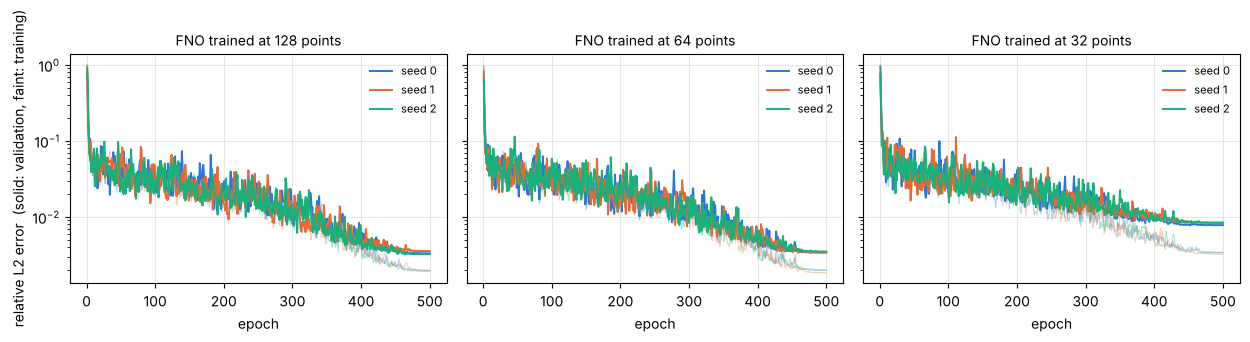

,grid,seed,best_val,best_epoch,epochs_run,seconds
0,128,0,0.003314,473,500,474.1
1,128,1,0.003543,490,500,444.2
2,128,2,0.003219,464,500,445.4
3,64,0,0.003432,490,500,286.4
4,64,1,0.003378,489,500,293.9
5,64,2,0.003455,484,500,268.9
6,32,0,0.007753,453,500,170.9
7,32,1,0.008340,486,500,174.7
8,32,2,0.008431,484,500,177.6


In [9]:
SEED_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]     # seed 0, 1, 2
grids = [n for n in (128, 64, 32) if any(os.path.exists(os.path.join(CKPT, f"{MODEL}_train{n}_seed{s}.pt")) for s in range(3))]
fig, axes = plt.subplots(1, len(grids), figsize=(4.2 * len(grids), 3.3), squeeze=False, sharey=True)
rows = []
for ax, n in zip(axes[0], grids):
    for s in range(3):
        path = os.path.join(CKPT, f"{MODEL}_train{n}_seed{s}.pt")
        if not os.path.exists(path):
            continue
        ck = torch.load(path, map_location="cpu", weights_only=False)
        h = ck.get("history")
        if h is None:
            continue
        ep = np.arange(1, len(h["val"]) + 1)
        ax.plot(ep, h["train"], color=SEED_COLORS[s], lw=0.8, alpha=0.35)
        ax.plot(ep, h["val"], color=SEED_COLORS[s], lw=1.4, label=f"seed {s}")
        rows.append(dict(grid=n, seed=s, best_val=ck["info"]["best_val"],
                         best_epoch=int(np.argmin(h["val"])) + 1, epochs_run=len(h["val"]),
                         seconds=ck["info"]["seconds"]))
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(f"{MODEL.upper()} trained at {n} points", fontsize=10)
    ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False)
axes[0][0].set_ylabel("relative L2 error  (solid: validation, faint: training)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

## 8. Sandbox: try other hyperparameters without touching the saved models

`try_fno(...)` trains **one** FNO with some settings changed, draws its live curve **on top of the saved model's
validation curve** (grey), and does **not** save anything. Use it to see whether a change helps before you retrain
for real.

Examples (uncomment one to run; 2–6 minutes each):
```python
try_fno(n_train=32, seed=0, lr=3e-3)                       # a larger learning rate (fast: 32-point grid)
try_fno(n_train=32, seed=0, epochs=250)                    # a shorter schedule
try_fno(n_train=32, seed=0, early_stopping_patience=40)    # see early stopping cut training short
try_fno(n_train=128, seed=0, modes_rule=lambda n: 16)      # keep only 16 modes, as in Li et al.
```
Important: choose hyperparameters by **validation** error only, never by the 256/512-point test results.
Otherwise the test is no longer a fair test.

In [10]:
def try_fno(n_train=128, seed=0, **changes):
    hp = {**HP, **changes}                                 # the current settings with your changes
    X, Y = load_train(n_train)
    modes = hp["modes_rule"](n_train)
    saved = os.path.join(CKPT, f"{MODEL}_train{n_train}_seed{seed}.pt")
    baseline = torch.load(saved, weights_only=False).get("history") if os.path.exists(saved) else None
    shown = {k: v for k, v in changes.items() if k != "modes_rule"}
    title = (f"sandbox: FNO at {n_train} pts, {modes} modes, seed {seed}, "
             + ", ".join(f"{k}={v}" for k, v in shown.items()))
    model, info, hist = train_fno(X, Y, tr, va, seed, hp, modes, monitor=LiveMonitor(title, baseline))
    msg = f"best validation error {info['best_val']:.5f} after {info['epochs']} epochs"
    if baseline:
        msg += f"  (saved model: {min(baseline['val']):.5f})"
    print(msg)
    return model

# try_fno(n_train=32, seed=0, early_stopping_patience=40)